# 04 · Modelización predictiva

**Objetivo:** pronosticar, a principios de cada mes, cuántos delitos de cada tipo se denunciarán en cada cantón durante ese mes, y detectar con antelación los cantones donde se espera un **aumento atípico**.

- **Unidad de predicción:** cantón × tipo de delito × mes (81 × 6 = 486 series mensuales).
- **Horizonte:** un mes. Todas las variables usan solo información disponible al cierre del mes anterior.
- **Esquema temporal** (nunca se usa el futuro para entrenar):
    - Selección de modelos y ajuste: entrenamiento 2015–2023, validación 2024.
    - **Prueba final:** reentrenamiento con 2015–2024 y evaluación en **enero de 2025 – septiembre de 2026** (21 meses que el modelo nunca vio).

In [1]:
import sys, time, warnings
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.stats import poisson
from sklearn.metrics import average_precision_score, roc_auc_score

from src import modelo, oij, viz

viz.estilo()
FIG = RAIZ / 'reports' / 'figures'
MODELOS = RAIZ / 'models'
MODELOS.mkdir(exist_ok=True)
DELITOS = oij.DELITOS
ET = viz.ETIQUETAS_DELITO
P = lambda s: pd.Period(s, 'M')

FIN_TRAIN_VAL, INI_VAL, FIN_VAL = P('2023-12'), P('2024-01'), P('2024-12')
FIN_TRAIN, INI_TEST = P('2024-12'), P('2025-01')

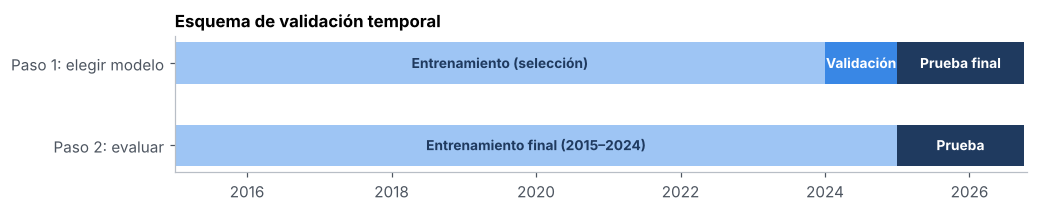

In [2]:
fig, ax = plt.subplots(figsize=(10, 1.6))
tramos = [('Entrenamiento (selección)', 2015, 2024, '#9ec5f4'), ('Validación', 2024, 2025, '#3987e5'),
          ('Prueba final', 2025, 2026.75, viz.AZUL)]
for i, (n, a, b, c) in enumerate(tramos):
    ax.barh(1, b - a, left=a, color=c, height=0.5)
    ax.text((a + b) / 2, 1, n, ha='center', va='center', color='white' if i else '#1f3a5f', fontsize=9, fontweight='bold')
ax.barh(0, 10, left=2015, color='#9ec5f4', height=0.5)
ax.text(2020, 0, 'Entrenamiento final (2015–2024)', ha='center', va='center', color=viz.AZUL, fontsize=9, fontweight='bold')
ax.barh(0, 1.75, left=2025, color=viz.AZUL, height=0.5)
ax.text(2025.875, 0, 'Prueba', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
ax.set_yticks([1, 0], ['Paso 1: elegir modelo', 'Paso 2: evaluar']); ax.set_xlim(2015, 2026.8); ax.grid(False)
ax.set_title('Esquema de validación temporal')
fig.savefig(FIG / '04_esquema_validacion.png')

## 1. Panel y variables explicativas

Las variables se construyen en `src/modelo.py`. Todas se calculan con datos hasta el mes anterior al que se predice.

In [3]:
t0 = time.time()
panel = modelo.construir_panel(RAIZ)
X_val = modelo.construir_variables(panel, RAIZ, FIN_TRAIN_VAL)   # índice estacional calculado hasta 2023
X_fin = modelo.construir_variables(panel, RAIZ, FIN_TRAIN)       # índice estacional calculado hasta 2024
print(f'Panel: {len(panel):,} filas ({panel.Canton.nunique()} cantones × {panel.Delito.nunique()} delitos × {panel.Mes.nunique()} meses), '
      f'{time.time() - t0:.0f} s')

Panel: 68,526 filas (81 cantones × 6 delitos × 141 meses), 61 s


In [4]:
descripcion = pd.DataFrame([
    ('Historia del propio cantón', 'lag_1, lag_2, lag_3, lag_12', 'Delitos de 1, 2, 3 y 12 meses antes'),
    ('Historia del propio cantón', 'media_3, media_12, tendencia', 'Promedios móviles y su cociente (aceleración reciente)'),
    ('Tasas', 'tasa_lag_1, tasa_media_12', 'Lo mismo por 100.000 habitantes'),
    ('Espacio', 'tasa_vecinos_lag_1', 'Tasa media de los cantones vecinos el mes anterior (notebook 03)'),
    ('Contexto nacional', 'nacional_lag_1', 'Total nacional del mismo delito el mes anterior'),
    ('Calendario', 'MesNum, fines_de_semana, dias_mes', 'Mes del año y su composición'),
    ('Calendario', 'Estacional_canton', 'Peso histórico de ese mes en el cantón (recoge fiestas locales)'),
    ('Calendario', 'pandemia', 'Indicador de marzo 2020 – diciembre 2021'),
    ('Estructura del cantón', 'log_poblacion, Grupo', 'Tamaño y perfil delictivo (notebook 03)'),
    ('Estructura del cantón', 'IDS_economica, IDS_educativa, IDS_salud, IDS_participacion', 'Índice de Desarrollo Social, sin la dimensión de seguridad'),
    ('Tipo de delito', 'Delito_cat', 'Permite que un único modelo aprenda patrones distintos por delito'),
], columns=['Grupo', 'Variables', 'Descripción'])
descripcion

,Grupo,Variables,Descripción
0,Historia del propio cantón,"lag_1, lag_2, lag_3, lag_12","Delitos de 1, 2, 3 y 12 meses antes"
1,Historia del propio cantón,"media_3, media_12, tendencia",Promedios móviles y su cociente (aceleración r...
2,Tasas,"tasa_lag_1, tasa_media_12",Lo mismo por 100.000 habitantes
3,Espacio,tasa_vecinos_lag_1,Tasa media de los cantones vecinos el mes ante...
4,Contexto nacional,nacional_lag_1,Total nacional del mismo delito el mes anterior
5,Calendario,"MesNum, fines_de_semana, dias_mes",Mes del año y su composición
6,Calendario,Estacional_canton,Peso histórico de ese mes en el cantón (recoge...
7,Calendario,pandemia,Indicador de marzo 2020 – diciembre 2021
8,Estructura del cantón,"log_poblacion, Grupo",Tamaño y perfil delictivo (notebook 03)
9,Estructura del cantón,"IDS_economica, IDS_educativa, IDS_salud, IDS_p...","Índice de Desarrollo Social, sin la dimensión ..."


In [5]:
def dividir(X, fin_train, ini_eval, fin_eval=None):
    d = X.dropna(subset=['lag_12', 'media_12'])
    tr = d[d['Mes'] <= fin_train]
    ev = d[d['Mes'] >= ini_eval]
    if fin_eval is not None:
        ev = ev[ev['Mes'] <= fin_eval]
    return tr, ev.copy()

tr_val, val = dividir(X_val, FIN_TRAIN_VAL, INI_VAL, FIN_VAL)
tr_fin, test = dividir(X_fin, FIN_TRAIN, INI_TEST)
print(f'Selección: {len(tr_val):,} filas de entrenamiento, {len(val):,} de validación')
print(f'Final:     {len(tr_fin):,} filas de entrenamiento, {len(test):,} de prueba ({test.Mes.min()} a {test.Mes.max()})')

Selección: 46,656 filas de entrenamiento, 5,832 de validación
Final:     52,488 filas de entrenamiento, 10,206 de prueba (2025-01 a 2026-09)


## 2. Modelos comparados

| Modelo | Idea | Por qué se incluye |
|---|---|---|
| Ingenuo: mes anterior | El próximo mes será igual al último | Referencia mínima |
| Ingenuo estacional | Igual al mismo mes del año anterior | Referencia que capta estacionalidad |
| Media móvil 3 y 12 meses | Promedio reciente | El criterio que usaría un analista sin modelo |
| SARIMA por serie | Modelo estadístico clásico de series temporales, uno por cada cantón y delito | Estándar en pronóstico; aprovecha la autocorrelación y la estacionalidad de cada serie |
| LightGBM global | Un único modelo de árboles potenciados para las 486 series, con distribución de Poisson | Comparte información entre cantones y combina historia, espacio, calendario y contexto socioeconómico |
| Combinación | Promedio de SARIMA y LightGBM | Combinar modelos distintos suele reducir el error |

**Detalles del LightGBM.** Se usa la pérdida de **Poisson**, adecuada para conteos. Además, el modelo parte de la media de los últimos 12 meses (*offset*) y aprende solo cuánto debe corregirla, lo que estabiliza el aprendizaje en las series pequeñas.

### 2.1 Ajuste del LightGBM en la validación 2024

Pequeña búsqueda de hiperparámetros: el número de árboles se fija con parada temprana.

In [6]:
V = modelo.VARIABLES
offset = lambda z: np.log(z['media_12'] + 0.5)

def entrenar_lgbm(tr, n_estimators=3000, ev=None, **params):
    base = dict(objective='poisson', learning_rate=0.03, num_leaves=15, min_child_samples=80,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, verbose=-1, random_state=0)
    base.update(params)
    m = lgb.LGBMRegressor(n_estimators=n_estimators, **base)
    kw = {}
    if ev is not None:
        kw = dict(eval_set=[(ev[V], ev['Delitos'])], eval_init_score=[offset(ev)],
                  callbacks=[lgb.early_stopping(150, verbose=False)])
    m.fit(tr[V], tr['Delitos'], init_score=offset(tr), **kw)
    return m

def predecir_lgbm(m, df):
    return np.exp(m.predict(df[V], raw_score=True) + offset(df).values)

busqueda = []
for hojas in (7, 15, 31):
    for minimo in (40, 80, 160):
        m = entrenar_lgbm(tr_val, ev=val, num_leaves=hojas, min_child_samples=minimo)
        busqueda.append({'num_leaves': hojas, 'min_child_samples': minimo, 'arboles': m.best_iteration_,
                         **modelo.metricas(val['Delitos'], pd.Series(predecir_lgbm(m, val), index=val.index))})
busqueda = pd.DataFrame(busqueda).sort_values('WAPE')
busqueda.round(4)

,num_leaves,min_child_samples,arboles,MAE,RMSE,WAPE
7,31,80,443,2.3584,4.0470,0.3196
6,31,40,609,2.3591,4.0734,0.3197
4,15,80,921,2.3592,4.0459,0.3197
0,7,40,1218,2.3607,4.0627,0.3199
5,15,160,750,2.3614,4.0799,0.3200
1,7,80,1579,2.3624,4.0627,0.3202
8,31,160,389,2.3631,4.0823,0.3203
3,15,40,748,2.3640,4.0882,0.3204
2,7,160,1217,2.3654,4.0885,0.3206


In [7]:
mejor = busqueda.iloc[0]
PARAMS = dict(num_leaves=int(mejor.num_leaves), min_child_samples=int(mejor.min_child_samples))
ARBOLES = int(mejor.arboles)
print('Configuración elegida:', PARAMS, '| árboles:', ARBOLES)

Configuración elegida: {'num_leaves': 31, 'min_child_samples': 80} | árboles: 443


### 2.2 SARIMA por serie

Para cada una de las 486 series se ajusta un SARIMA(1,0,1)(1,0,0)₁₂ sobre el logaritmo de los conteos, con la pandemia como variable exógena. El modelo se ajusta una vez con los datos de entrenamiento y después se actualiza mes a mes con cada nuevo dato observado, sin reestimar sus parámetros, igual que se usaría en producción. Las series que no convergen usan la media de los últimos 12 meses.

In [8]:
t0 = time.time()
val = val.merge(modelo.sarima_un_paso(X_val, FIN_TRAIN_VAL, INI_VAL, FIN_VAL), on=['Canton', 'Delito', 'Mes'])
print(f'SARIMA en validación: {time.time() - t0:.0f} s')

Series sin convergencia: 0
SARIMA en validación: 179 s


## 3. Prueba final: enero 2025 – septiembre 2026

Se reentrena con todos los datos hasta diciembre de 2024 y se evalúa en los 21 meses siguientes.

In [9]:
lgbm_final = entrenar_lgbm(tr_fin, n_estimators=ARBOLES, **PARAMS)
lgbm_final.booster_.save_model(str(MODELOS / 'lgbm_poisson.txt'))

t0 = time.time()
test = test.merge(modelo.sarima_un_paso(X_fin, FIN_TRAIN, INI_TEST), on=['Canton', 'Delito', 'Mes'])
print(f'SARIMA en prueba: {time.time() - t0:.0f} s')

for df, m in [(val, None), (test, lgbm_final)]:
    if m is None:
        m = entrenar_lgbm(tr_val, n_estimators=ARBOLES, **PARAMS)
    df['Ingenuo'] = df['lag_1']
    df['Estacional'] = df['lag_12']
    df['Media 3'] = df['media_3']
    df['Media 12'] = df['media_12']
    df['LightGBM'] = predecir_lgbm(m, df)
    df['Combinación'] = (df['LightGBM'] + df['SARIMA']) / 2

MODELOS_EVAL = ['Ingenuo', 'Estacional', 'Media 3', 'Media 12', 'SARIMA', 'LightGBM', 'Combinación']

Series sin convergencia: 0
SARIMA en prueba: 242 s


### 3.1 Precisión global

- **MAE:** error absoluto medio, en número de delitos por cantón y mes.
- **RMSE:** penaliza más los errores grandes.
- **WAPE:** error absoluto total dividido entre el total de delitos. Es la métrica principal porque se interpreta como un porcentaje.

Como referencia se calcula el **piso de Poisson**: el error que tendría incluso un modelo perfecto, porque los delitos son eventos aleatorios. Si un cantón espera 4 delitos en un mes, puede tener 2 o 7 por puro azar.

In [10]:
def piso_poisson(lam):
    k = np.arange(0, 600)
    return np.array([(poisson.pmf(k, l) * np.abs(k - l)).sum() for l in lam])

res = {}
for nombre, df in [('Validación 2024', val), ('Prueba 2025–2026', test)]:
    res[nombre] = pd.DataFrame({m: modelo.metricas(df['Delitos'], df[m]) for m in MODELOS_EVAL}).T
piso = piso_poisson(test['LightGBM'].values).sum() / test['Delitos'].sum()
tabla = pd.concat(res, axis=1).round(3)
print(f'Piso de Poisson (WAPE mínimo esperable en la prueba): {piso:.3f}')
tabla

Piso de Poisson (WAPE mínimo esperable en la prueba): 0.248


Validación 2024               Prueba 2025–2026              
                        MAE   RMSE   WAPE              MAE   RMSE   WAPE
Ingenuo               2.932  5.483  0.397            2.793  5.715  0.432
Estacional            3.195  5.655  0.433            3.105  6.281  0.480
Media 3               2.514  4.543  0.341            2.431  4.991  0.375
Media 12              2.431  4.293  0.329            2.354  4.952  0.364
SARIMA                2.415  4.295  0.327            2.456  4.883  0.379
LightGBM              2.358  4.047  0.320            2.233  4.451  0.345
Combinación           2.338  4.057  0.317            2.294  4.530  0.354

Ingenuo       -0.187
Estacional    -0.319
Media 3       -0.032
Media 12       0.000
SARIMA        -0.043
LightGBM       0.051
Combinación    0.025
Name: Mejora frente a Media 12, dtype: float64

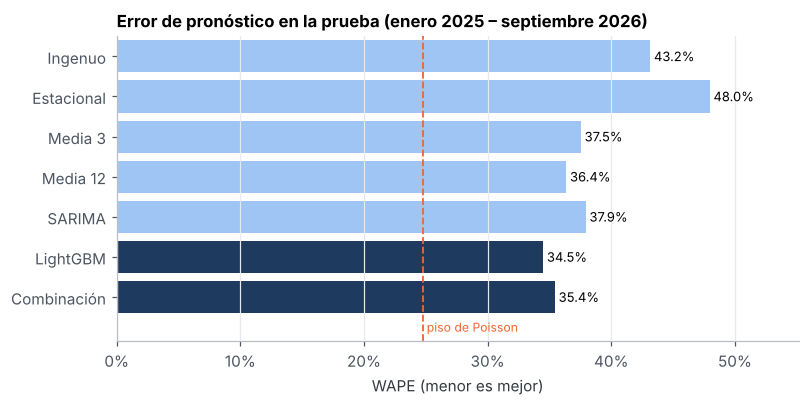

In [11]:
w = res['Prueba 2025–2026']['WAPE']
mejora = 1 - w / w['Media 12']
fig, ax = plt.subplots(figsize=(8, 3.6))
colores = [viz.AZUL if m in ('LightGBM', 'Combinación') else '#9ec5f4' for m in w.index]
ax.barh(w.index[::-1], w.values[::-1], color=colores[::-1])
ax.axvline(piso, color=viz.NARANJA, ls='--', lw=1.2)
ax.text(piso, -0.75, ' piso de Poisson', color=viz.NARANJA, fontsize=8, va='center')
for i, v in enumerate(w.values[::-1]):
    ax.text(v + 0.003, i, f'{v:.1%}', va='center', fontsize=8.5)
ax.set_xlim(0, w.max() * 1.15); ax.set_ylim(-1.1, len(w) - 0.5)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1)); ax.set_xlabel('WAPE (menor es mejor)'); ax.grid(axis='y', visible=False)
ax.set_title('Error de pronóstico en la prueba (enero 2025 – septiembre 2026)')
fig.savefig(FIG / '04_error_modelos.png')
mejora.round(3).rename('Mejora frente a Media 12')

In [12]:
por_delito = test.groupby('Delito').apply(
    lambda g: pd.Series({m: modelo.metricas(g['Delitos'], g[m])['WAPE'] for m in ['Media 12', 'SARIMA', 'LightGBM', 'Combinación']}))
por_delito.index = [ET[d] for d in por_delito.index]
por_delito.round(3)

,Media 12,SARIMA,LightGBM,Combinación
Asalto,0.336,0.344,0.305,0.318
Homicidio,0.813,0.741,0.813,0.764
Hurto,0.299,0.324,0.281,0.296
Robo,0.391,0.430,0.369,0.391
Robo de vehículo,0.390,0.395,0.384,0.379
Tacha de vehículo,0.426,0.427,0.419,0.416


### 3.2 Detección de aumentos atípicos: la alerta temprana

Predecir el volumen de delitos de un cantón grande es relativamente fácil: su historia reciente ya lo dice. Lo valioso para un sistema de alerta es **anticipar los aumentos**: los meses en que un cantón supera claramente su nivel habitual.

Se define un **aumento atípico** cuando los delitos del mes superan a la vez:

- un 30 % más que la media de los 12 meses anteriores, y
- esa media más dos desviaciones típicas de Poisson (para no confundir azar con aumento),

con un mínimo de 5 delitos. Cada modelo puntúa el riesgo de aumento como su predicción dividida entre la media de 12 meses.

In [13]:
def marcar_aumentos(df):
    umbral = np.maximum(df['media_12'] * 1.3, df['media_12'] + 2 * np.sqrt(df['media_12'] + 1))
    df['Aumento'] = ((df['Delitos'] > umbral) & (df['Delitos'] >= 5)).astype(int)

for df in (val, test):
    marcar_aumentos(df)
print(f"Aumentos atípicos en la prueba: {test['Aumento'].sum()} de {len(test):,} casos ({test['Aumento'].mean():.1%})")

def precision_top(df, col, k=10):
    """De las k alertas más altas de cada mes, qué proporción fue un aumento real."""
    aciertos = []
    for _, g in df[df['media_12'] >= 3].groupby('Mes'):
        riesgo = g[col] / (g['media_12'] + 0.5)
        aciertos.append(g.loc[riesgo.nlargest(k).index, 'Aumento'].mean())
    return np.mean(aciertos)

candidatos = {'Tendencia reciente (Media 3 / Media 12)': 'Media 3', 'Mes anterior / Media 12': 'Ingenuo',
              'SARIMA': 'SARIMA', 'LightGBM': 'LightGBM', 'Combinación': 'Combinación'}
def evaluar_alertas(df):
    return pd.DataFrame({n: {
        'AUC': roc_auc_score(df['Aumento'], df[c] / (df['media_12'] + 0.5)),
        'Precisión media (AP)': average_precision_score(df['Aumento'], df[c] / (df['media_12'] + 0.5)),
        'Aciertos en las 10 alertas del mes': precision_top(df, c),
    } for n, c in candidatos.items()}).T

alertas_val = evaluar_alertas(val)
alertas = evaluar_alertas(test)
pd.concat({'Validación 2024': alertas_val, 'Prueba 2025–2026': alertas}, axis=1).round(3)

Aumentos atípicos en la prueba: 439 de 10,206 casos (4.3%)


Validación 2024                       \
                                                    AUC Precisión media (AP)   
Tendencia reciente (Media 3 / Media 12)           0.630                0.059   
Mes anterior / Media 12                           0.632                0.055   
SARIMA                                            0.688                0.075   
LightGBM                                          0.692                0.103   
Combinación                                       0.703                0.085   

                                                                            \
                                        Aciertos en las 10 alertas del mes   
Tendencia reciente (Media 3 / Media 12)                              0.083   
Mes anterior / Media 12                                              0.092   
SARIMA                                                               0.083   
LightGBM                                                             0.158   
Combinación                                                          0.117   

                                        Prueba 2025–2026                       \
                                                     AUC Precisión media (AP)   
Tendencia reciente (Media 3 / Media 12)            0.641                0.064   
Mes anterior / Media 12                            0.627                0.059   
SARIMA                                             0.662                0.066   
LightGBM                                           0.712                0.117   
Combinación                                        0.695                0.079   

                                                                            
                                        Aciertos en las 10 alertas del mes  
Tendencia reciente (Media 3 / Media 12)                              0.081  
Mes anterior / Media 12                                              0.076  
SARIMA                                                               0.071  
LightGBM                                                             0.152  
Combinación                                                          0.119

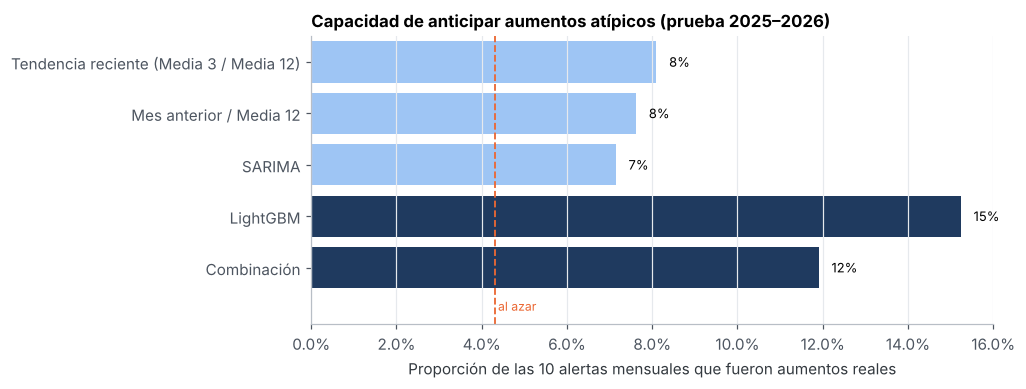

In [14]:
base = test['Aumento'].mean()
fig, ax = plt.subplots(figsize=(8, 3.4))
v = alertas['Aciertos en las 10 alertas del mes']
colores = [viz.AZUL if n in ('LightGBM', 'Combinación') else '#9ec5f4' for n in v.index]
ax.barh(v.index[::-1], v.values[::-1], color=colores[::-1])
ax.axvline(base, color=viz.NARANJA, ls='--', lw=1.2)
ax.text(base, -0.75, ' al azar', color=viz.NARANJA, fontsize=8, va='center')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
for i, x in enumerate(v.values[::-1]):
    ax.text(x + 0.003, i, f'{x:.0%}', va='center', fontsize=8.5)
ax.set_ylim(-1.1, len(v) - 0.5); ax.set_xlabel('Proporción de las 10 alertas mensuales que fueron aumentos reales'); ax.grid(axis='y', visible=False)
ax.set_title('Capacidad de anticipar aumentos atípicos (prueba 2025–2026)')
fig.savefig(FIG / '04_alertas.png')

### 3.3 Cobertura de la priorización por volumen

Si cada mes se priorizan los 10 cantones con más delitos previstos (para cada tipo de delito), ¿qué parte de los delitos reales ocurre en ellos? El techo es lo que se cubriría sabiendo de antemano los resultados reales.

In [15]:
def cobertura(df, col, k=10):
    return np.mean([g.nlargest(k, col)['Delitos'].sum() / g['Delitos'].sum() for _, g in df.groupby(['Mes', 'Delito'])])

cob = pd.Series({m: cobertura(test, m) for m in ['Estacional', 'Media 12', 'SARIMA', 'LightGBM', 'Combinación', 'Delitos']})
cob.rename({'Delitos': 'Techo (resultado real)'}).round(3).rename('Cobertura top 10')

Estacional                0.513
Media 12                  0.541
SARIMA                    0.539
LightGBM                  0.542
Combinación               0.541
Techo (resultado real)    0.588
Name: Cobertura top 10, dtype: float64

## 4. Resultados, fortalezas y debilidades

Las cifras exactas están en las tablas anteriores; esta síntesis se basa en ellas.

In [16]:
resumen = pd.DataFrame({
    'WAPE prueba': res['Prueba 2025–2026']['WAPE'],
    'Aciertos alertas top 10': alertas['Aciertos en las 10 alertas del mes'].rename(
        {'Tendencia reciente (Media 3 / Media 12)': 'Media 3', 'Mes anterior / Media 12': 'Ingenuo'}),
}).loc[['Ingenuo', 'Estacional', 'Media 3', 'Media 12', 'SARIMA', 'LightGBM', 'Combinación']]
resumen.round(3)

,WAPE prueba,Aciertos alertas top 10
Ingenuo,0.432,0.076
Estacional,0.480,NaN
Media 3,0.375,0.081
Media 12,0.364,NaN
SARIMA,0.379,0.071
LightGBM,0.345,0.152
Combinación,0.354,0.119


| Modelo | Fortalezas | Debilidades |
|---|---|---|
| Ingenuos y medias móviles | Simples, sin entrenamiento, difíciles de batir en volumen | No anticipan cambios: solo repiten el pasado |
| SARIMA | Interpretable, captura bien la estacionalidad de cada serie, competitivo en delitos poco frecuentes | Un modelo por serie: no comparte información entre cantones; costoso de mantener (486 modelos); no usa variables externas |
| LightGBM global | Un solo modelo; combina historia, vecinos, calendario y contexto socioeconómico; el mejor en volumen y en alertas | Menos transparente (se explica en el notebook 05); requiere cuidar que ninguna variable use información futura |
| Combinación | Reduce el error al mezclar dos enfoques distintos | Hereda la complejidad de ambos |

### Elección del modelo

La elección se justifica con la **validación 2024**, no con la prueba, para no hacer trampa: en validación, la combinación y el LightGBM tienen un error de volumen casi idéntico, pero el LightGBM es claramente mejor anticipando aumentos (más aciertos en las 10 alertas del mes) y es un único modelo en lugar de 487. Por eso se elige el **LightGBM como motor del sistema de alerta**. La prueba 2025–2026 confirma la elección.

## 5. Conclusiones

1. **El LightGBM es el mejor modelo en la prueba final:** reduce el WAPE de la mejor referencia simple (media de 12 meses) de 36,4 % a 34,5 %, un 5 % menos de error. El SARIMA, pese a ser el estándar clásico, no supera a la media móvil en la prueba.
2. **Buena parte del error es azar irreducible:** incluso un modelo perfecto tendría un WAPE de 24,8 % (piso de Poisson). El LightGBM cierra en torno a un 16 % de la distancia entre la media móvil y ese límite.
3. **El valor principal está en las alertas:** de las 10 alertas mensuales del LightGBM, el 15 % son aumentos reales, frente al 7–8 % de los métodos simples y al 4 % del azar. Es decir, **duplica la precisión** para anticipar dónde va a subir el delito.
4. **Para priorizar por volumen no hace falta un modelo complejo:** todos cubren alrededor del 54 % de los delitos con los 10 cantones priorizados, cerca del techo del 59 %. Los cantones grandes son siempre los mismos y su historia lo dice. El aporte del modelo está en detectar cambios, no en repetir el ranking.
5. **El homicidio es el delito más difícil:** con pocos casos por cantón y mes, el azar domina (WAPE en torno al 80 %). Para este delito el SARIMA es algo mejor; en el sistema final conviene presentarlo a escala regional o trimestral.
6. **Limitación:** los meses más recientes pueden estar algo subestimados porque el OIJ añade denuncias tardías (notebook 01).

## 6. Guardar predicciones

In [17]:
cols = ['Canton', 'Provincia', 'Delito', 'Mes', 'Delitos', 'media_12', 'Aumento'] + MODELOS_EVAL
test[cols].assign(Mes=test['Mes'].astype(str)).to_parquet(RAIZ / 'data' / 'processed' / 'predicciones_prueba.parquet', index=False)
pd.Series({'arboles': ARBOLES, **PARAMS, 'fin_entrenamiento': str(FIN_TRAIN)}).to_json(MODELOS / 'lgbm_config.json')
print('Modelo y predicciones guardados')

Modelo y predicciones guardados
